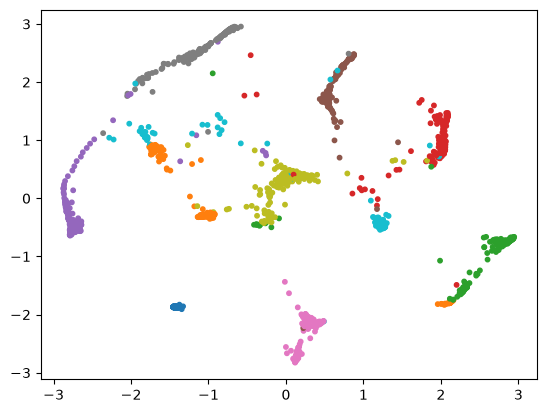

In [6]:
import matplotlib.pyplot as plt
import umap
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler

from imste import IteratedMinimumSpanningTreeEmbedder

digits = load_digits()
X = StandardScaler().fit_transform(digits["data"])

imste_embedding = IteratedMinimumSpanningTreeEmbedder(
    random_state=42,
).fit_transform(X)
plt.scatter(imste_embedding[:, 0], imste_embedding[:, 1], c=digits.target, cmap="tab10", s=10)

/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)


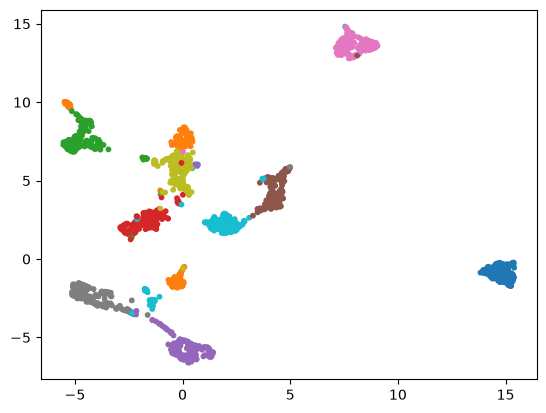

In [8]:
import matplotlib.pyplot as plt
import umap
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler

from imste import IteratedMinimumSpanningTreeEmbedder

digits = load_digits()
X = StandardScaler().fit_transform(digits["data"])

umap_embedding = umap.UMAP().fit_transform(X)

plt.scatter(umap_embedding[:, 0], umap_embedding[:, 1], c=digits.target, cmap="tab10", s=10)

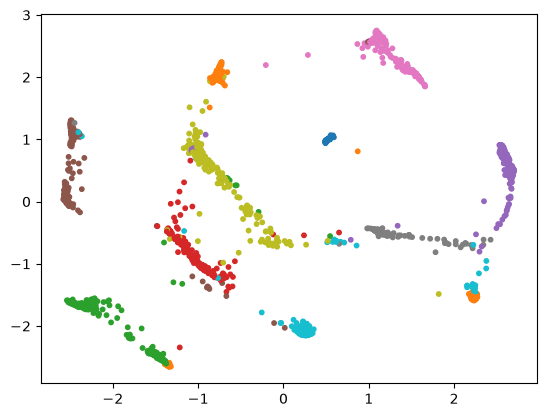

In [7]:
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from sklearn.datasets import load_digits
from scipy.spatial.distance import cdist
from sklearn.preprocessing import StandardScaler

from imste import IteratedMinimumSpanningTreeEmbedder

digits = load_digits()
X = StandardScaler().fit_transform(digits.data)

# The complete digits distance matrix is small enough to hold in memory.
distance_matrix = cdist(X, X, metric="euclidean")
distance_graph = csr_matrix(distance_matrix)

graph_embedding = IteratedMinimumSpanningTreeEmbedder(
    random_state=42,
).fit_graph_transform(distance_graph)

plt.scatter(graph_embedding[:, 0], graph_embedding[:, 1], c=digits.target, cmap="tab10", s=10)
